This is the code used for assignment 2 for Introduction to Computational Science, by Kay Maas and Antonia Glaum

# Problem 1: Event Driven SIR model

## Problem 1.0.1: Preperations

Here we try out different stochastic models and make generalized methods so we can easily change between and test methods:

In [33]:
import matplotlib.pyplot as plt
import numpy as np
import math
import json
import os


plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
})

We want to implement a stochastic SIR model. First we define our rates. These are inherent of the SIR model:

In [34]:
def get_rates(state, beta, gamma, mu, ve):
    S, I, R, N = state
    N = S + I + R
    # The population has died out
    if N <= 0:
        return np.zeros(6)
    # We calculate the rate
    r_birth = ve * N
    r_inf = beta * S * I / N
    r_rec = gamma * I
    r_dS = mu * S
    r_dI = mu * I
    r_dR = mu * R
    # We place these rates in an array
    rates = np.array([r_birth, r_inf, r_dS, r_rec, r_dI, r_dR])
    # And make sure that no value is negative
    return np.maximum(rates, 0)

We want to easily apply different noise functions:

In [35]:
def noise_deterministic(rates, dt, rng):
    # No noise, just the SIR model
    return rates * dt

def noise_euler_maruyama(rates, dt, rng):
    return rates * dt + np.sqrt(rates * dt) * rng.standard_normal(rates.size)

def noise_poisson(rates, dt, rng): 
    return rng.poisson(rates * dt)

We then define the stochastic SIR which can easily implement different noise methods

In [36]:
def stochastic_SIR(state0, t_end, dt, beta, gamma, mu, ve, noise = noise_poisson, seed=None):
    """
    state: [susceptible, infected, recovered, population size]
    beta: rate of infection
    gamma: rate of recovery
    mu: death rate
    ve: birth rate
    """
    rng = np.random.default_rng(seed)
    n_steps = int(t_end / dt)
    dynamics = np.zeros((n_steps + 1, 4))
    dynamics[0] = state0
    squar_dt = np.sqrt(dt)

    for k in range(n_steps):
        state = dynamics[k]
        S, I, R, N = state
        # We get the rates of change
        rates = get_rates(state, beta, gamma, mu, ve)

        # We apply the noise function
        birth, inf, dS, rec, dI, dR = noise(rates, dt, rng)

        # Changes over this time step
        dSdt = birth - inf - dS
        dIdt = inf - rec - dI
        dRdt = rec - dR

        # Update the state: old value + change, kept non-negative
        S_new = max(S + dSdt, 0)
        I_new = max(I + dIdt, 0)
        R_new = max(R + dRdt, 0)
        N_new = max(S_new + I_new + R_new, 1e-9)

        dynamics[k + 1] = [S_new, I_new, R_new, N_new]
    return dynamics

We define our variables:

In [37]:
# SIR parameters
state0 = [990,10,0, 1000]
beta = 2
gamma = 1
mu = 0.1
ve = 0.1
# Run variables
t_end = 100
dt = 0.01

We then run our method

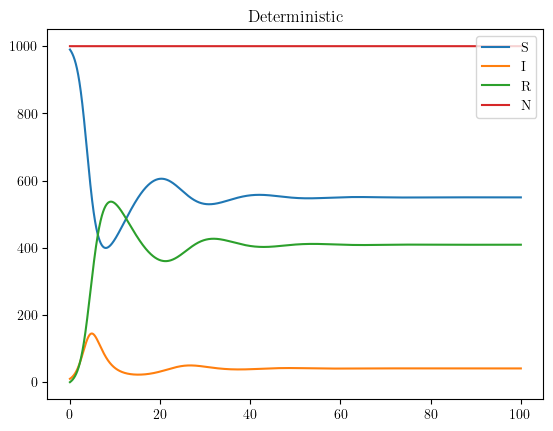

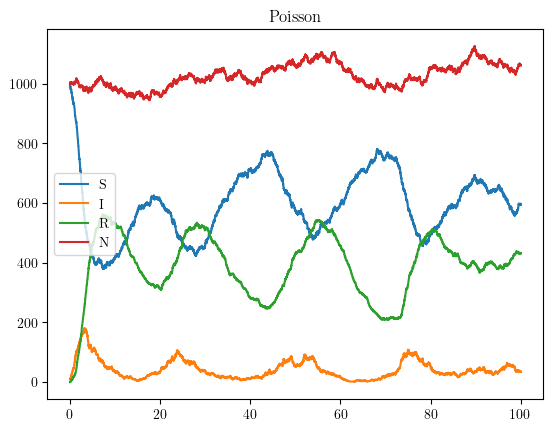

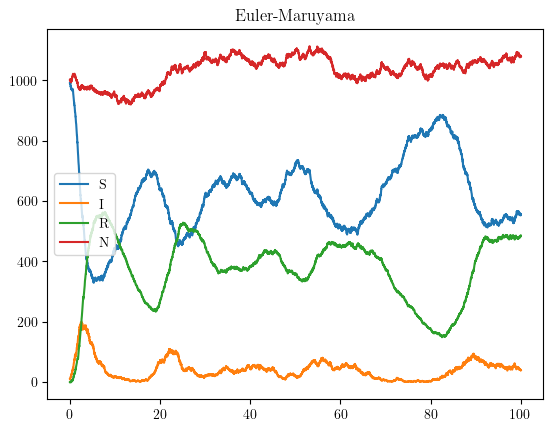

In [38]:
noise_functions = {"Deterministic":noise_deterministic, 
                   "Poisson": noise_poisson, 
                   "Euler-Maruyama": noise_euler_maruyama}

def plot_dynamics(dynamics, name=""):
    time = np.arange(dynamics.shape[0]) * dt 
    plt.plot(time, dynamics[:, 0], label="S")
    plt.plot(time, dynamics[:, 1], label="I")
    plt.plot(time, dynamics[:, 2], label="R")
    plt.plot(time, dynamics[:, 3], label="N")
    plt.title(name)
    plt.legend()
    plt.show()
    
for f in noise_functions.keys():
    function = noise_functions[f]
    dynamics = stochastic_SIR(state0, t_end, dt, beta, gamma, mu, ve, noise= function, seed=0)
    plot_dynamics(dynamics, name=f)

We also want to implement a event driven SIR model. For this we need functions that can find the next event. This is dependent on the rates if change in the population

In [39]:
# Each event has effect on one portion of the population
# This array represents how each rate effects the population
EFFECTS = np.array([
    [ 1,  0,  0, 1],   # birth
    [-1,  1,  0, 0],   # infection
    [-1,  0,  0,-1],   # S death
    [ 0, -1,  1, 0],   # recovery
    [ 0, -1,  0,-1],   # I death
    [ 0,  0, -1,-1],   # R death
])


def next_event_direct(state, rates, rng):
    """
    This is Gillespie direct method, the focuss of our analysis
    """
    # We want to determine when the next event occurs
    # for this, we sum the rates. Aka. we look how much the 
    # the system changes (this is just a vecotrized method for speed)
    cumulative_rates = np.cumsum(rates)
    total = cumulative_rates[-1]
    if total <= 0:
        # If the change is negative or 0, no event can happen.
        # in this case, we move tau to infinity:
        return np.inf, None
    # We determine the shift in time, aka tau:
    tau = rng.exponential(1/total)
    # We choose which event we want to perform 
    threshold = rng.random() * total
    event_index = np.searchsorted(
        cumulative_rates, threshold, side="right"
    )
    # we perform the event to determine the next state
    next_state = state + EFFECTS[event_index]
    return tau, next_state

def next_event_first_reaction(state, rates, rng):
    """
    Gillespie first-reaction method: each event draws its own
    waiting time, and the earliest one wins.
    """
    # We only look at the active rates, aka, the positive rates
    active = rates > 0
    # If none of the rates are active, than no event will take place
    if not active.any():
        return np.inf, None
    # We deterimine the taus first by dinding them for all 
    # active rates. For the non-active rates, we set tau at
    # infinity
    taus = np.full(rates.size, np.inf)
    taus[active] = rng.exponential(1 / rates[active])
    # We then find the lowest tau, this is thet event that
    # we perform
    event_index = np.argmin(taus)
    # We determine the next state from this event
    state = state + EFFECTS[event_index]
    return taus[event_index], state

In [40]:
def event_driven_SIR(state0, t_end, beta, gamma, mu, ve,
                     next_event=next_event_direct, seed=None):
    rng = np.random.default_rng(seed)
    t = 0.0
    tau = 0.0
    # We take a copy of the current state and 
    # place it in the states
    times = [t] 
    states = [state0]
    state = state0.copy()
    # We perform the next event till we exeed t_end
    while t < t_end:
        # We get the rates
        rates = get_rates(state, beta, gamma, mu, ve)
        # We look for the next event
        tau, state = next_event(state, rates, rng)
        if t+tau > t_end:
            break
        # We move forward in time
        t += tau
        # We add the new state and time to the array
        times.append(t)
        states.append(state.copy())
    # We return the final time and states array, representing the dynamics
    return np.array(times), np.array(states)

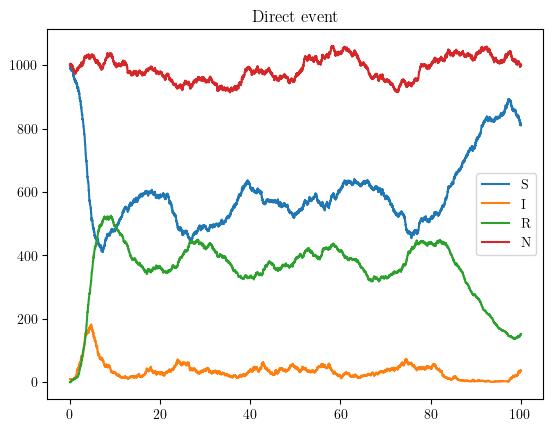

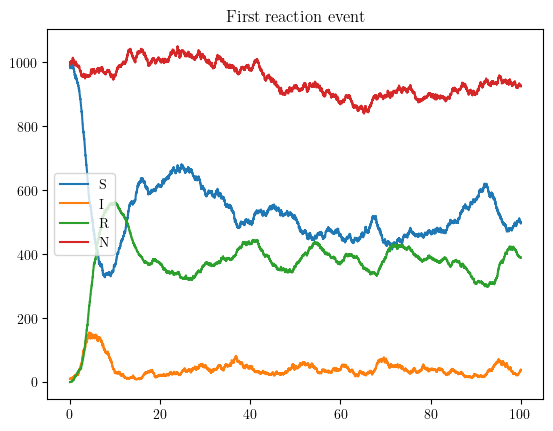

In [41]:
def to_grid(times, states, t_end, dt):
    """
    We resample the states so that they 
    take the same form as the SIR model
    """
    grid = np.arange(0, t_end + dt / 2, dt)
    idx = np.searchsorted(times, grid, side="right") - 1
    S = states[idx]
    return np.column_stack([S, S.sum(axis=1)])

events = {"Direct event": next_event_direct,
         "First reaction event": next_event_first_reaction}

for f in events.keys():
    function = events[f]
    time, states = event_driven_SIR(state0, t_end, beta, gamma, mu, ve, next_event=function, seed=0)
    dynamics = to_grid(time, states, t_end, dt)
    plot_dynamics(dynamics, name=f)

## Problem 1.0.2. Collecting data 

Now that we have our different models, we want to analyze the Gillespie's Direct Algorithm. We want to collect data on which we can perform the statistics. For this we have to create a experimental setup. For our experiments we will set $\mu = v$, keeping the population size roughly constant. 

We will run our experiments for 100 different seeds (seed=0,1,...,99), with the following baseline:

\begin{align*}
    \beta &= 2\\
    \gamma &= 1 \\
    \mu=v&=0.1\\
    N&=1000\\
    I/N&=0.01\\
    S/N&=0.99 \\
    t_{\text{end}} &= 500\\
    dt &= 0.01
\end{align*}

For each experiment, we will change one of these parameters, using between 3 to 4 different values for each, and run the Gillespie's Direct Algorithm with these parameter values. We will furthermore run a deterministic SIR model with these parameter values. 


In [98]:
# Baseline every experiment varies ONE of these and keeps the rest\
# ToDo keep beta and gamma in [0,1] and use one year periods 
BASELINE = dict(
    n=1000,
    portion_infected=0.01,
    beta=2,
    gamma=1,
    mu=0.1,
    ve=0.1,
    t_end=200,
    dt=0.1,
)

SEEDS = range(100)

def make_state0(n, portion_infected):
    # We want at least 1 infected in the population
    I0 = max(1, round(portion_infected * n))
    return [n - I0, I0, 0, n]

def run_experiment(param, values, seeds = SEEDS, baseline = BASELINE,
                   next_event=next_event_direct, ve_equals_mu=True,
                   outdir="data", name=None):
    """
    param:      key of the baseline that is being varied
    values:     the values to try for that parameter
    baseline:   the baseline dictionary
    seeds:      seeds for the stochastic runs
    ve_equals_mu: if True, the birth rate follows mu when mu is varied
    """
    name = name or param 
    os.makedirs(outdir, exist_ok=True)
    results = {}
    print_statement = len(seeds)/10

    for value in values:
        # We make a copy of the baseline, so it is never modified
        p = dict(baseline)
        p[param] = value
        if ve_equals_mu and param == "mu":
            p["ve"] = value

        print("=" * 30)
        print(f"Running {param}={value}\t:", end="")
        
        # We make the initial state (different for different n)
        state0 = make_state0(p["n"], p["portion_infected"])

        # Deterministic run (same for every seed)
        det_dynamics = stochastic_SIR(state0, p["t_end"], p["dt"],
                                      p["beta"], p["gamma"], p["mu"], p["ve"],
                                      noise=noise_deterministic)
        
        # We perform the model for the different parameters
        dynamics_per_seed = []
        for i, seed in enumerate(seeds):
            if i % print_statement == 0:
                print(".", end="", flush=True)
            time, states = event_driven_SIR(state0, p["t_end"],
                                            p["beta"], p["gamma"], p["mu"], p["ve"],
                                            next_event=next_event, seed=seed)
            dynamics_per_seed.append(to_grid(time, states, p["t_end"], p["dt"]))
        
        dynamics_per_seed = np.array(dynamics_per_seed)

        # Both arrays must share the same time grid
        if dynamics_per_seed.shape[1] != det_dynamics.shape[0]:
            print(f"\nWARNING: grid mismatch {dynamics_per_seed.shape[1]} "
                  f"vs {det_dynamics.shape[0]}")

        np.save(f"{outdir}/{name}_{value}_sto.npy", dynamics_per_seed)
        np.save(f"{outdir}/{name}_{value}_det.npy", det_dynamics)
        results[value] = (dynamics_per_seed, det_dynamics)
        print("Complete")
    print("=" * 30)
    return results

The values that we want to investegate are:


\begin{align*}
    \beta &\in \{0.5, 1.2, 2, 5\}\\
    \gamma &\in \{0.5, 1, 2\}\\
    \mu=v& \in \{0.01,0.1,0.5\}\\
    N&\in \{100,1000,10000\}
\end{align*}

We furthermore want to run one experimient where $\mu \neq v$. For this we will run:

\begin{align*}
    (\mu, v) &= (0.10, 0.09)\\
    (\mu, v) &= (0.10, 0.10)\\
    (\mu, v) &= (0.10, 0.11)
\end{align*}


In [43]:
# Comment this note after running the experiment.
# No use in running it again 

VALUES = dict(
    n=[100, 1000, 10000],
    beta=[0.5, 1.2, 2, 5],
    gamma=[0.01, 0.1, 0.5],
    mu=[0.05, 0.1, 0.2],
    ve= [0.09, 0.10, 0.11]
)
#
# parameters = ["n", "beta", "mu", "gamma"]
# for p in parameters:
#     print(f"___EXPERIMENT {p}___")
#     run_experiment(p,VALUES[p])
#
# print(f"___EXPERIMENT ve___")
# run_experiment("ve",VALUES["ve"], ve_equals_mu=False)

Lastely, we create a method to easily load the data:

In [44]:
def load_experiment(experiment, values, outdir="data"):
    stochastic = {v: (np.load(f"{outdir}/{experiment}_{v}_sto.npy")) for v in values}
    determinis = {v: (np.load(f"{outdir}/{experiment}_{v}_det.npy")) for v in values}
    return stochastic, determinis

## Problem 1.1: Variability and Negative Co-variance

Now that we have our data, we can perform our statistical tests. We will start by looking at the variability and negative covariance:

In [45]:
def var_cov(stochastic, deterministic, values):
    info = {}
    for v in values: 
        # We first load all the data
        dynamics = stochastic[v]
        det_dynamics = deterministic[v]
        
        S_runs = dynamics[:,:,0]
        I_runs = dynamics[:,:,1]
        # We store all the info in a dictionary
        info_per_parameter = {}

        # Then we determine the mean values
        S_mean = np.mean(S_runs, axis=0)
        info_per_parameter["S-mean"] = S_mean
        I_mean = np.mean(I_runs, axis=0)
        info_per_parameter["I-mean"] = I_mean

        # Sample variances across runs at each time point
        S_var = np.var(S_runs, axis=0, ddof=1)
        info_per_parameter["S-var"] = S_var
        I_var = np.var(I_runs, axis=0, ddof=1)
        info_per_parameter["I-var"] = I_var

        # Sample covariance between S and I at each time point
        n_runs = S_runs.shape[0]
        covariance = np.sum(
            (S_runs - S_mean) * (I_runs - I_mean),
            axis=0,
        ) / (n_runs - 1)
        info_per_parameter["Cov"] = covariance

        # Deterministic output
        det_dynamics = np.array(det_dynamics)

        info_per_parameter["S-diff"] = det_dynamics[:,0] - S_mean
        info_per_parameter["I-diff"] = det_dynamics[:,1] - I_mean
        info[v] = info_per_parameter
    # We return all the info
    return info

In [68]:
def plot_var_cov(stats, param, show_s = False):
    for n in list(stats):
        fig, axes = plt.subplots(
        1, 4,
        figsize=(18, 3.5),
        sharex=True,
        squeeze=False,
        constrained_layout=True,
        )
        data = stats[n]
        time = np.arange(len(data["S-mean"])) * dt

        # 1. Stochastic means and deterministic trajectories.
        # Your differences are defined as deterministic minus stochastic mean.
        ax = axes[0, 0]
        if show_s:
            ax.plot(time, data["S-mean"], color="tab:blue", label="S mean")
            ax.plot(time, data["S-mean"] + data["S-diff"],
                color="tab:blue", linestyle="--", label="S deterministic")
        ax.plot(time, data["I-mean"], color="tab:orange", label="I mean")
        ax.plot(time, data["I-mean"] + data["I-diff"],
                color="tab:orange", linestyle="--", label="I deterministic")
        ax.set_title(f"{param} = {n:,}: mean vs deterministic")
        ax.set_ylabel("Individuals")

        # 2. Variances across runs at each time point.
        ax = axes[0, 1]
        if show_s:
            ax.plot(time, data["S-var"], color="tab:blue", label="Var(S)")
        ax.plot(time, data["I-var"], color="tab:orange", label="Var(I)")
        ax.set_title(f"{param} = {n:,}: variance")
        ax.set_ylabel("Individuals squared")

        # 3. Covariance across runs at each time point.
        ax = axes[0, 2]
        ax.plot(time, data["Cov"], color="tab:blue", label="Cov(S, I)")
        ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
        ax.set_title(f"{param} = {n:,}: covariance")
        ax.set_ylabel("Individuals squared")

        # 4. Signed differences between deterministic output and stochastic means.
        ax = axes[0, 3]
        if show_s:
            ax.plot(time, data["S-diff"], color="tab:blue", label="S difference")
        ax.plot(time, data["I-diff"], color="tab:orange", label="I difference")
        ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
        ax.set_title(f"{param} = {n:,}: deterministic − mean")
        ax.set_ylabel("Individuals")

        for ax in axes[0]:
            ax.set_xlabel("Time")
            ax.grid(alpha=0.25)
            ax.legend(fontsize=8)

        plt.show()

### Problem 1.1.1 Population

First we look at different population size $N$. We will analyze the runs for the experiment for $N=100,1000,10000$

[100, 1000, 10000]


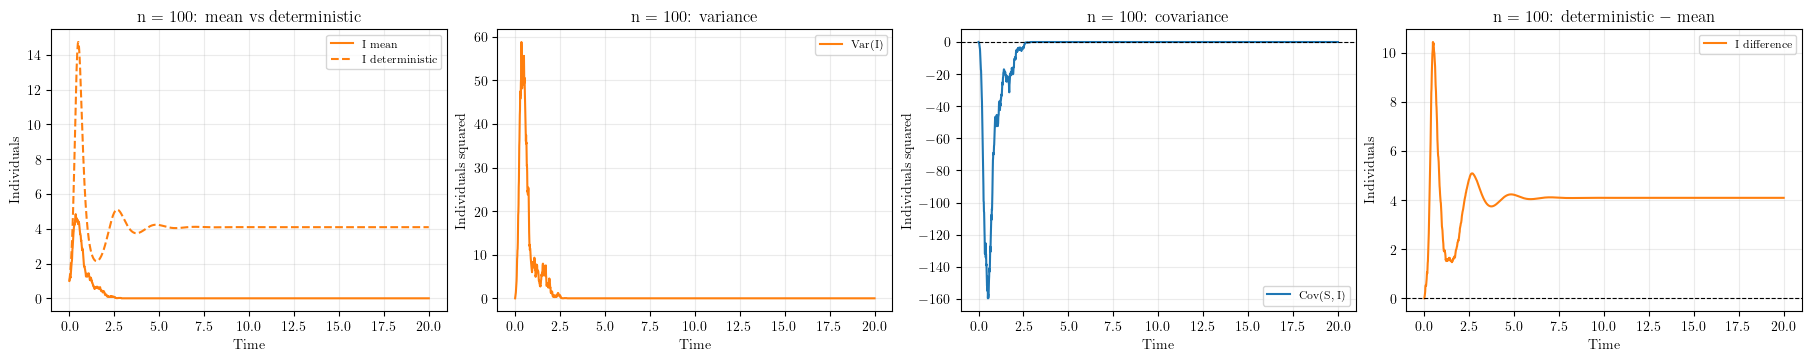

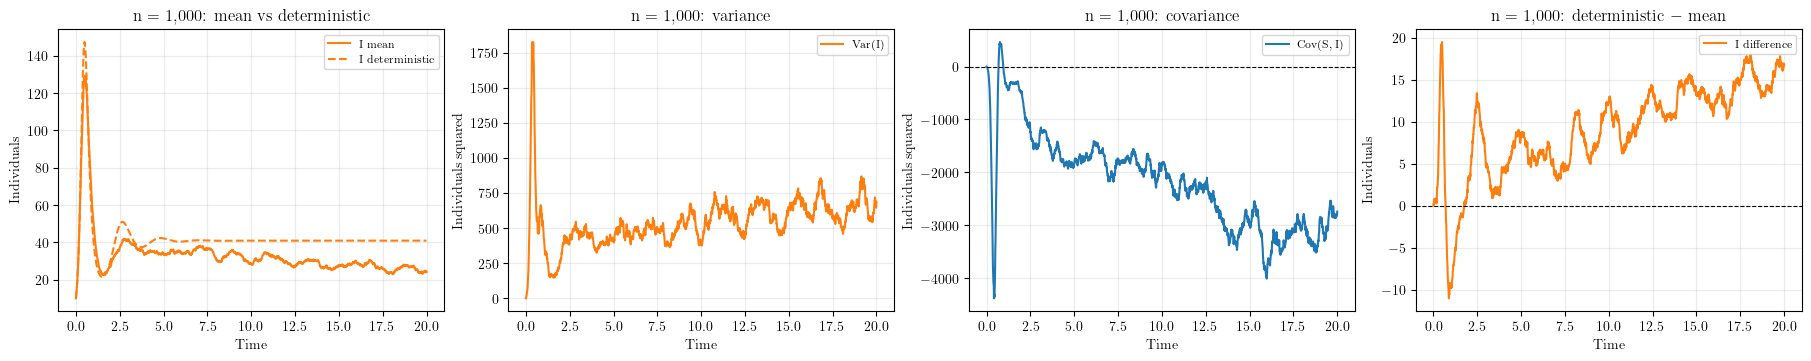

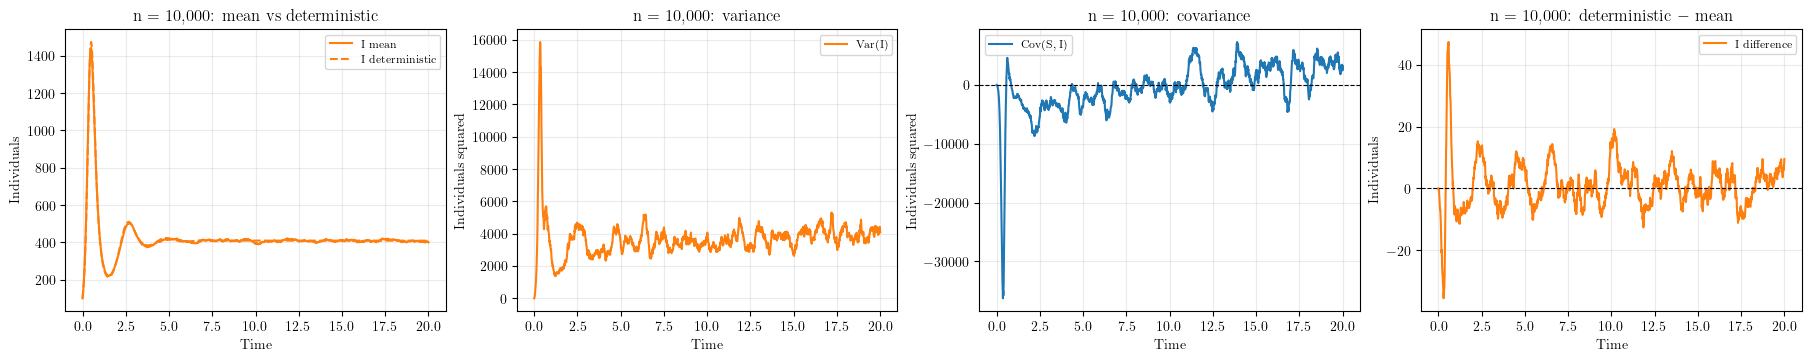

In [69]:
#ToDo values are hard set now for testing, update to: VALUES["n"]
print(VALUES["n"])
stochastic, deterministic = load_experiment("n", VALUES["n"])
stats = var_cov(stochastic, deterministic, VALUES["n"])
plot_var_cov(stats, "n")

### Problem 1.1.2 Beta

Now we will look at different reproduction numbers $R_0$, by keeping $\gamma=1$ and $\mu=0.1$ constant, and implementing different values for $\beta=0.5,1.2,2,5$. This will result in $R_0 \approx 0.45,1.1, 1.8, 4.5$

[0.5, 1.2, 2, 5]


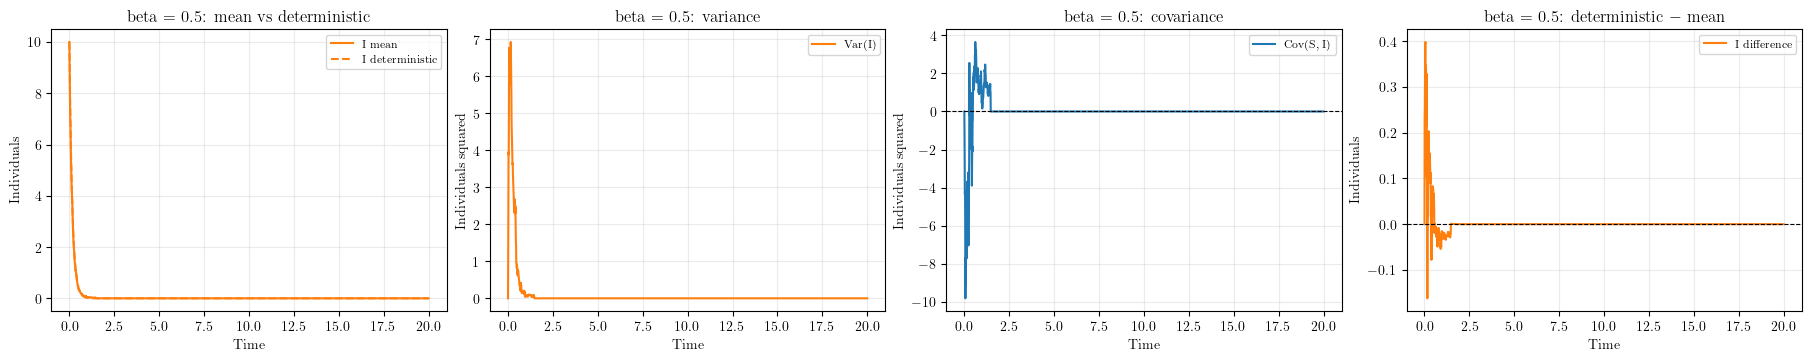

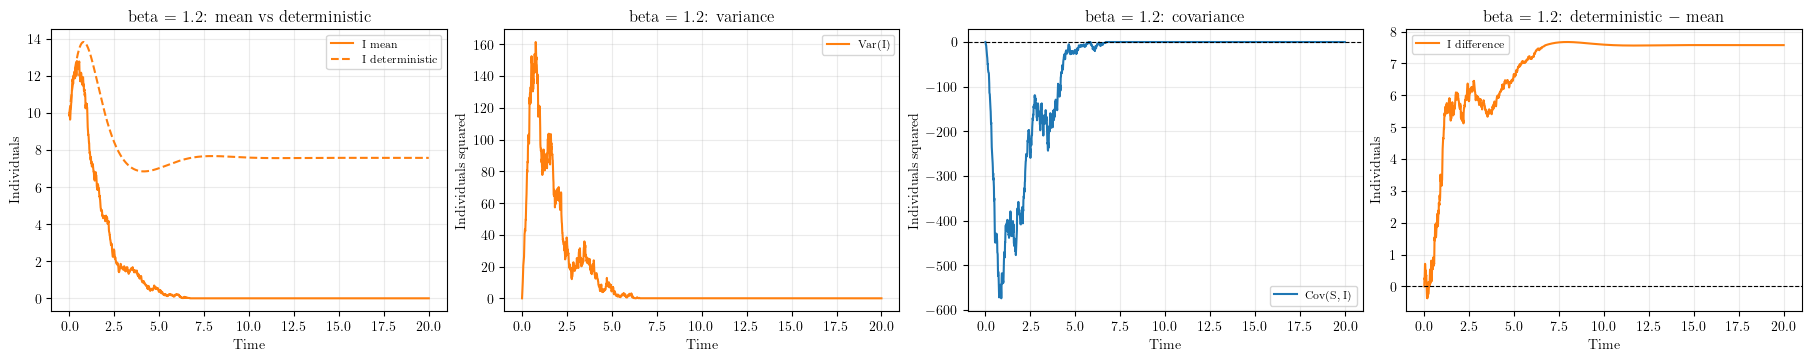

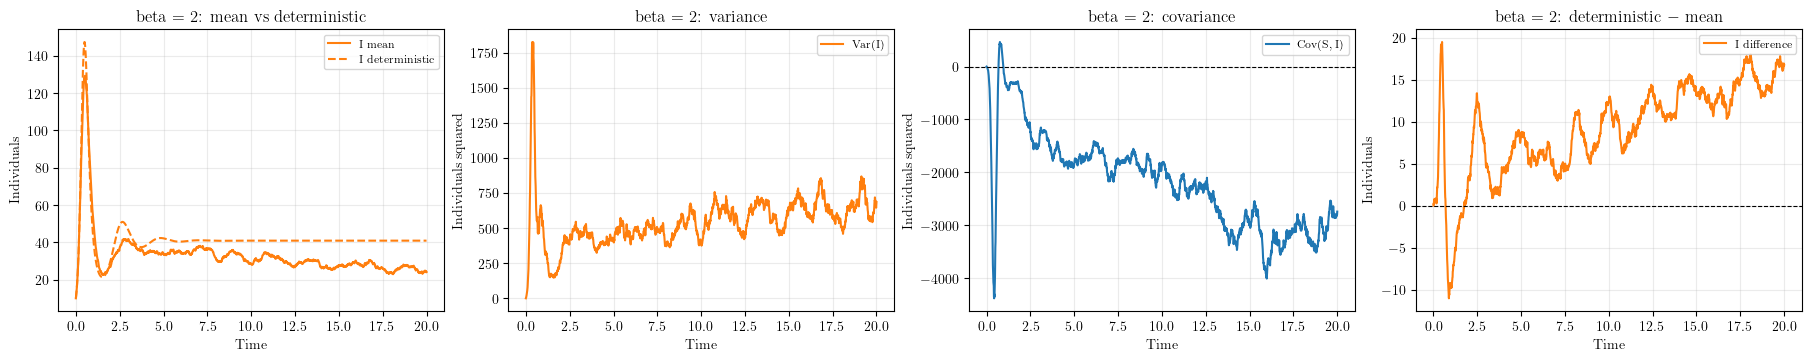

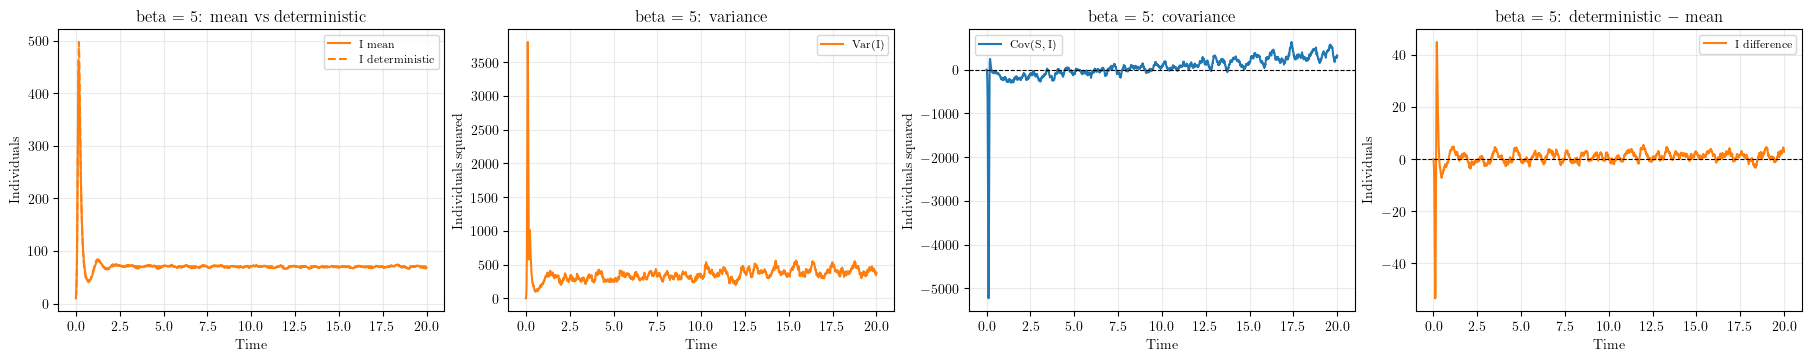

In [70]:
print(VALUES["beta"])
stochastic, deterministic = load_experiment("beta", VALUES["beta"])
stats = var_cov(stochastic, deterministic, VALUES["beta"])
plot_var_cov(stats, "beta")

### Problem 1.1.3 Gamma

I will now just print everything, what we will look at speaks for itself:

[0.01, 0.1, 0.5]


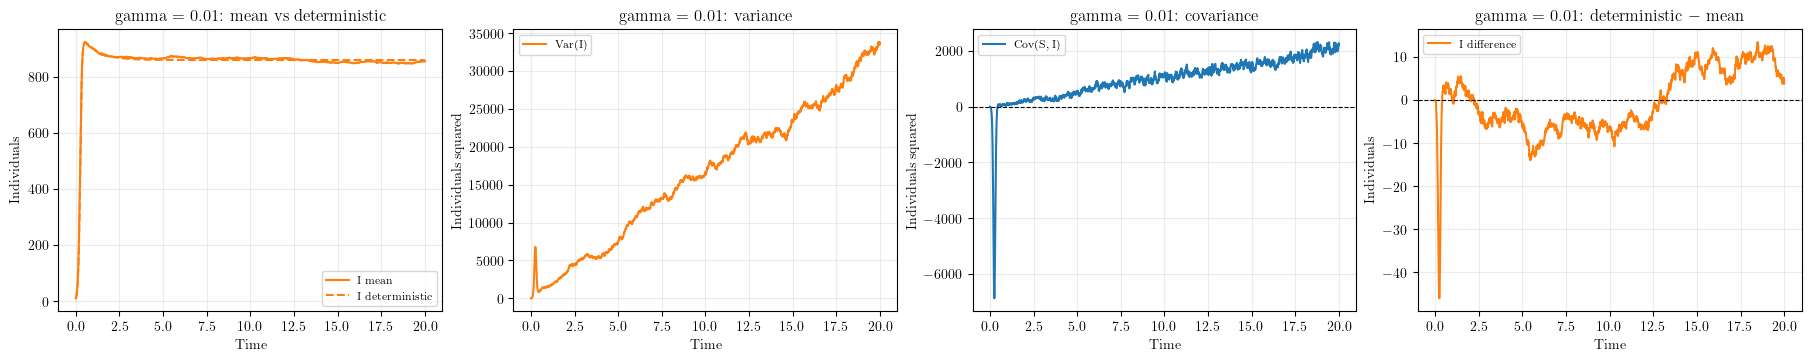

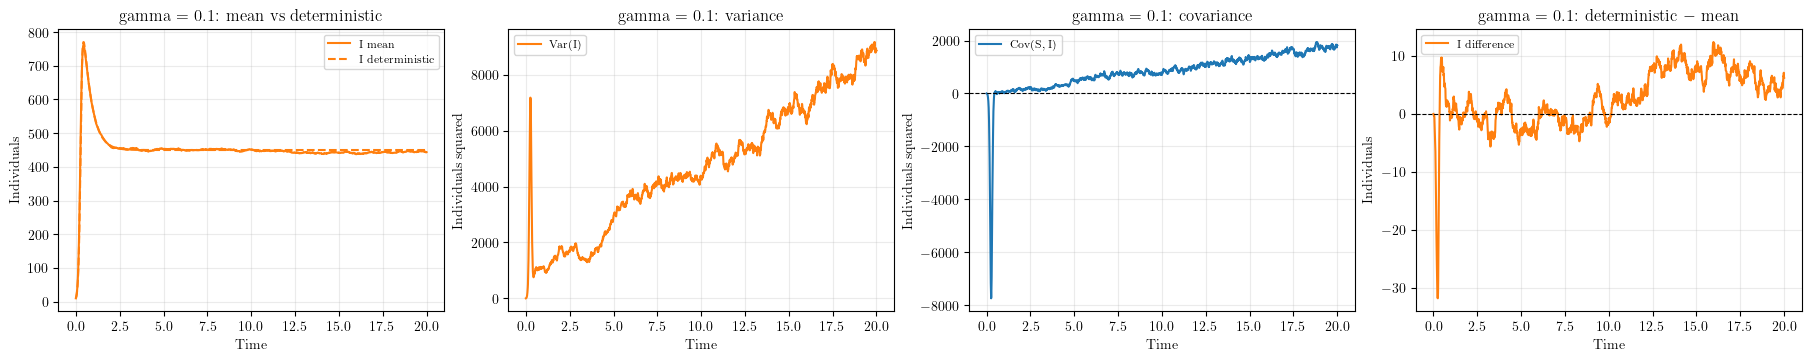

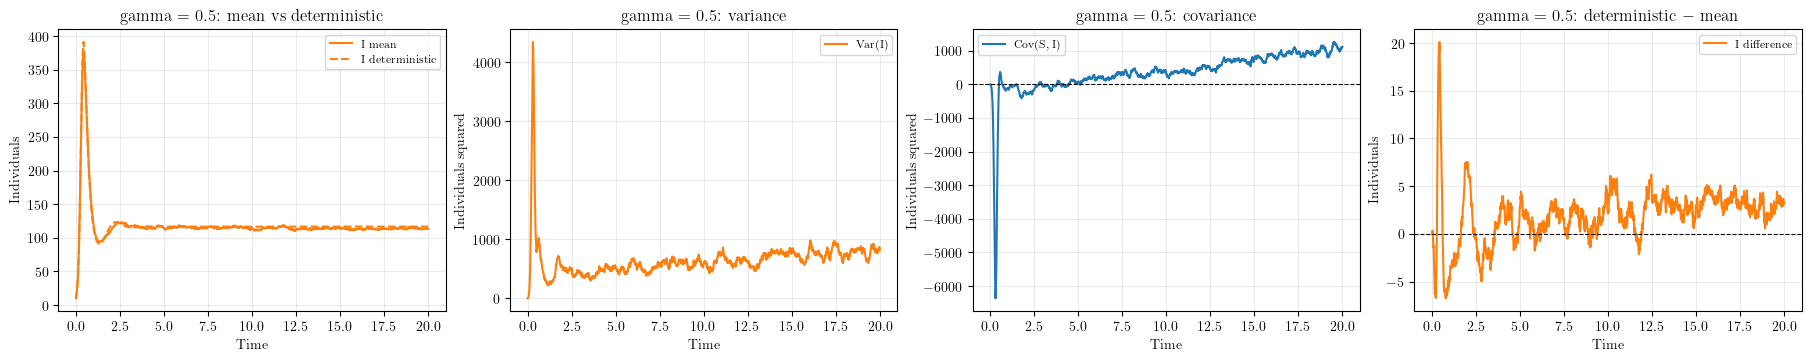

In [71]:
print(VALUES["gamma"])
stochastic, deterministic = load_experiment("gamma", VALUES["gamma"])
stats = var_cov(stochastic, deterministic, VALUES["gamma"])
plot_var_cov(stats, "gamma")

### Problem 1.1.4 Mu

[0.05, 0.1, 0.2]


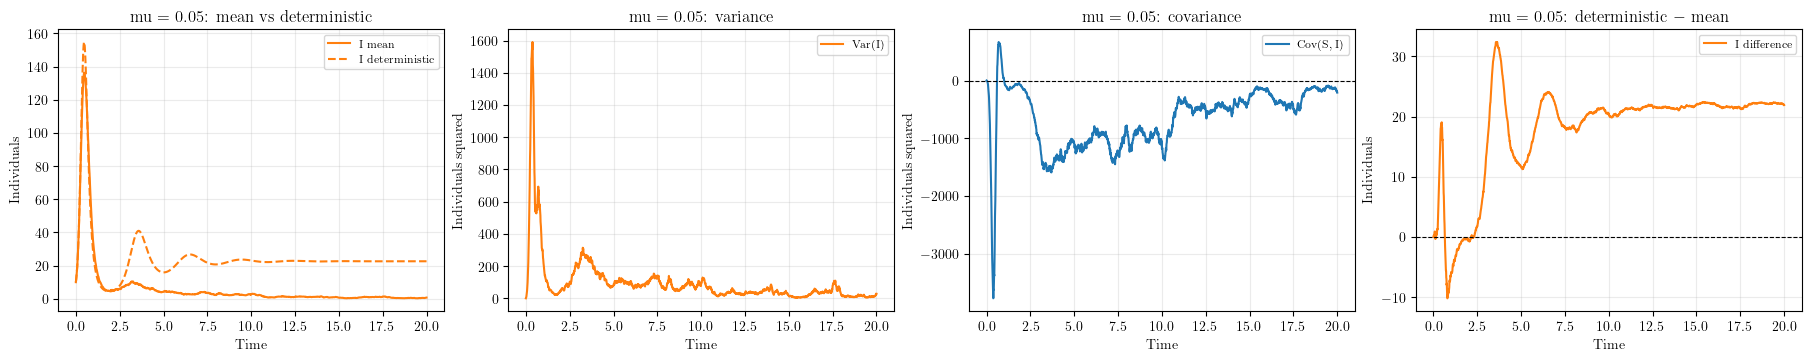

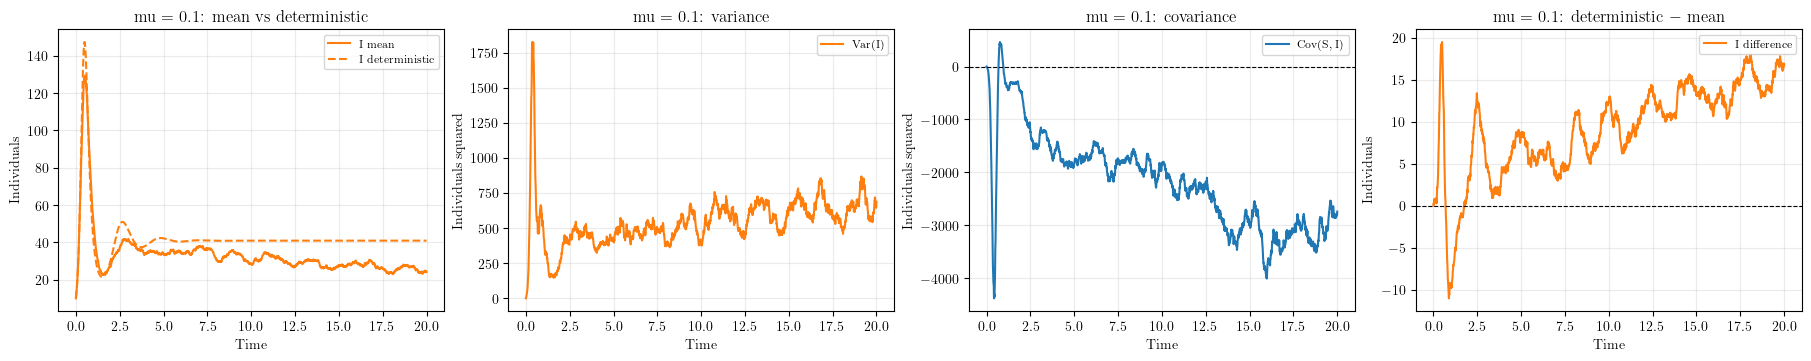

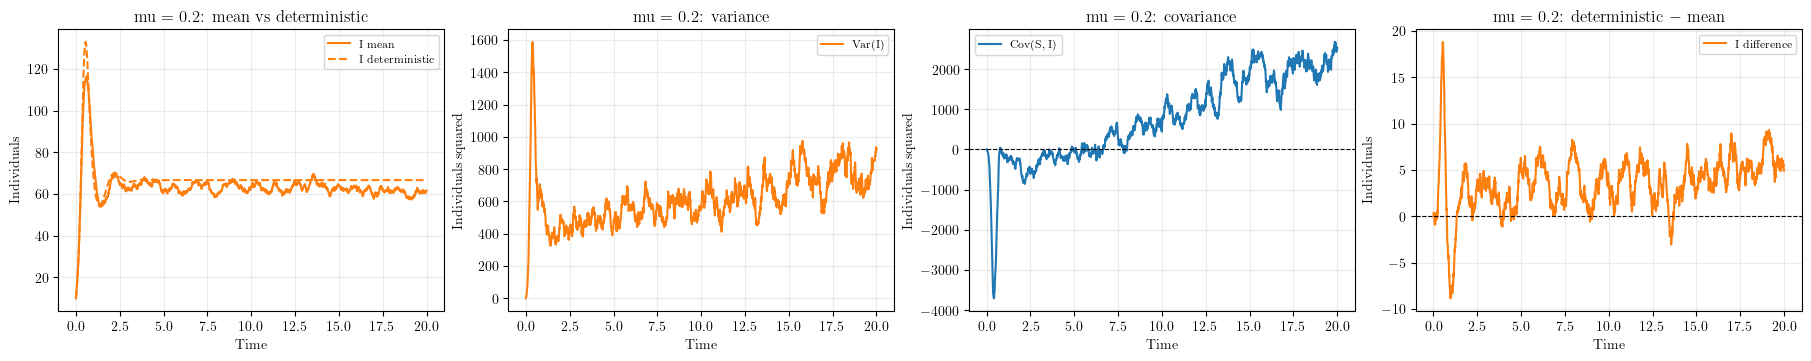

In [72]:
print(VALUES["mu"])
stochastic, deterministic = load_experiment("mu", VALUES["mu"])
stats = var_cov(stochastic, deterministic, VALUES["mu"])
plot_var_cov(stats, "mu")

### Problem 1.1.5 Ve

[0.09, 0.1, 0.11]


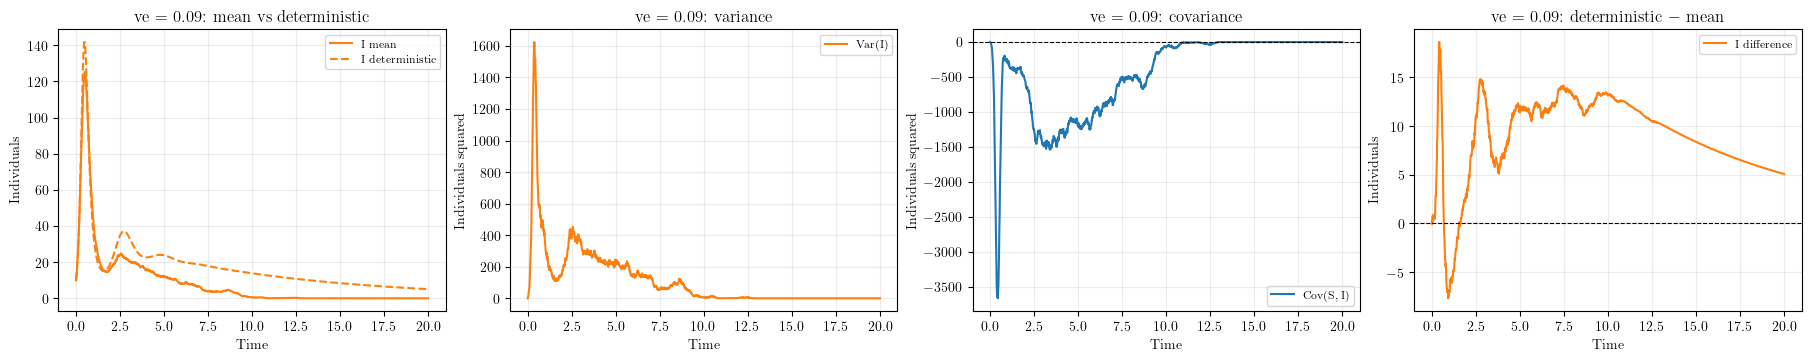

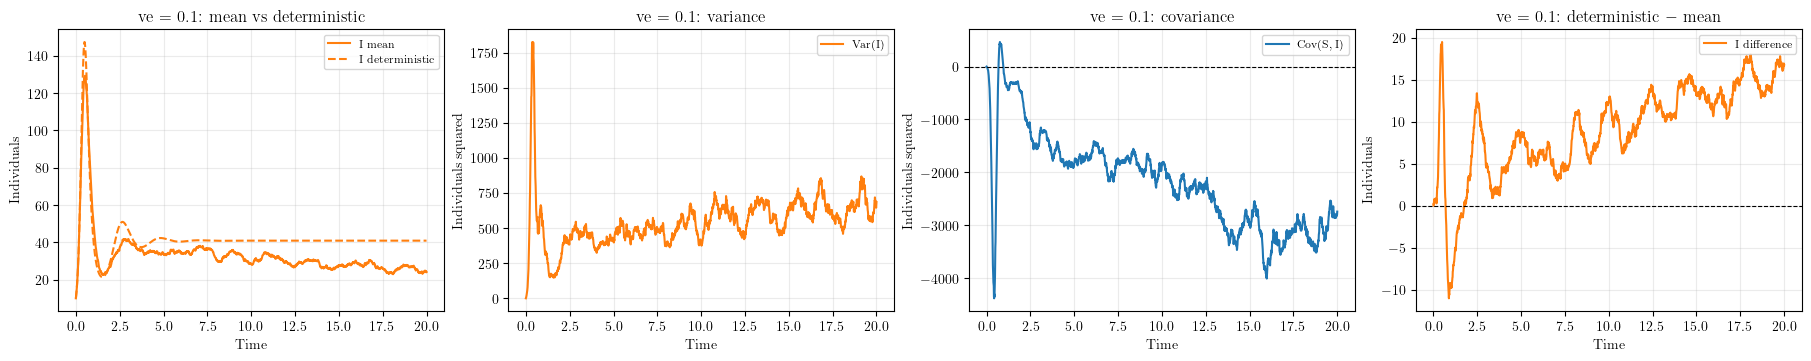

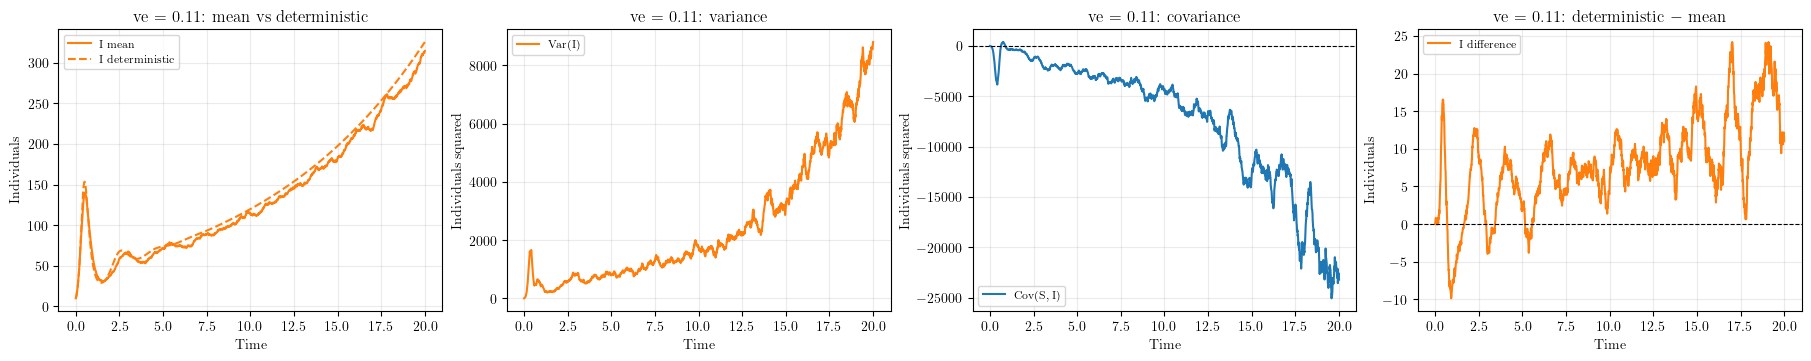

In [73]:
print(VALUES["ve"])
stochastic, deterministic = load_experiment("ve", VALUES["ve"])
stats = var_cov(stochastic, deterministic, VALUES["ve"])
plot_var_cov(stats, "ve")

## Problem 1.2. Stochastic Resonance and transient

First, we can use the theory at hand to find the predictions of our model. Here we only look at the cases where $\mu = v$, which implies that $R_0=\beta/(\gamma+\mu)$.

In these cases, we can easily find the fixed points:
\begin{align*}
    S^* &= 1/R_0 \\
    I^* &= \frac{\mu(R_0-1)}{\beta}
\end{align*}

We furthemore know from the theory that the Jacobian $J$ has the following properties:

\begin{align*}
    \operatorname{tr}(J) &= -\mu R_0\\
    \det(J) &= \mu(\gamma + \mu)(R_0 - 1)
\end{align*}

The natural frequency $\omega$ and dampening rate $d$ are:

\begin{align*}
    \omega O^2 &= \mu (\gamma + \mu)(R_0-1)-\tfrac{1}{4}(\mu R_0)^2\\
    d &= \tfrac{1}{2}\mu R_0 
\end{align*}

We can easily define a method that finds these values for our system:

In [52]:
def equilibrium_theory(beta, gamma, mu):
    R0 = beta / (gamma + mu)
    s_star, i_star = 1 / R0, mu * (R0 - 1) / beta
    damping = mu * R0 / 2
    w2 = mu * (gamma + mu) * (R0 - 1) - damping**2
    omega0 = np.sqrt(w2) if w2 > 0 else np.nan      # nan = no oscillation (overdamped)
    return dict(R0=R0, S=s_star, I=i_star, omega0=omega0,
                period=2 * np.pi / omega0, damping=damping)

This means that the baseline has the following properties:

In [54]:
EQUILIBRIUM_BASELINE = equilibrium_theory(BASELINE["beta"], BASELINE["gamma"], BASELINE["mu"])
EQUILIBRIUM_BASELINE

{'R0': 1.8181818181818181,
 'S': 0.55,
 'I': 0.04090909090909091,
 'omega0': np.float64(0.28589427624575253),
 'period': np.float64(21.977303602184076),
 'damping': 0.09090909090909091}

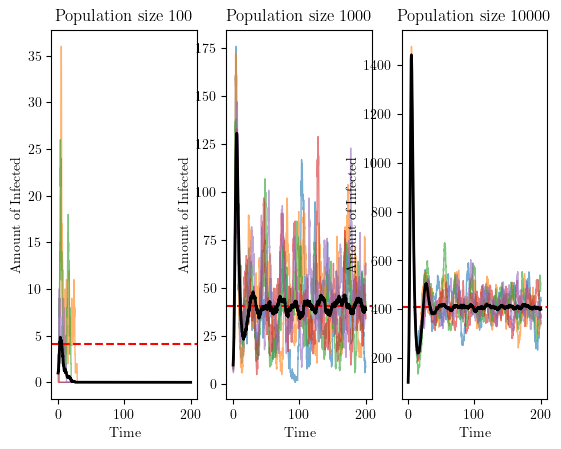

In [55]:
#ToDo values are hard set now for testing, update to: VALUES["n"]
stochastic, deterministic = load_experiment("n",  VALUES["n"])
fig, axes = plt.subplots(1, len( VALUES["n"]))
for i,v in enumerate(VALUES["n"]):
    I = stochastic[v][:,:,1]
    if v != 100:
        alive = I[:, -1] > 0
        I= I[alive]
    time = np.arange(len(I[0]))*BASELINE["dt"]
    # We plot 5 individual runs
    for r in I[:5]:                            
        axes[i].plot(time, r, alpha=0.6, lw=1)
    # Plot the equilibrium
    axes[i].axhline(EQUILIBRIUM_BASELINE["I"] * v, color="r", ls="--", label="Fixed point")
    # And the stochastic behavior
    axes[i].plot(time, I.mean(axis=0), "k", lw=2, label="Mean over all runs")
    axes[i].set_xlabel("Time")
    axes[i].set_ylabel("Amount of Infected")
    axes[i].set_title(f"Population size {v}")
plt.show()

As you can see, the baseline has a period of around 22, as can be seen in the deterministic case:

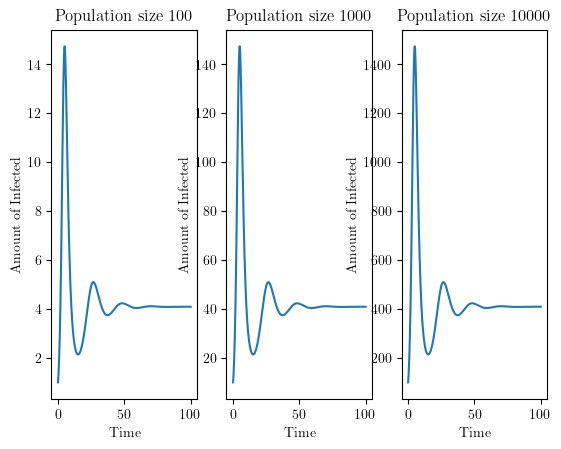

In [56]:
#ToDo values are hard set now for testing, update to: VALUES["n"]
stochastic, deterministic = load_experiment("n",  VALUES["n"])
fig, axes = plt.subplots(1, len( VALUES["n"]))
for i,v in enumerate(VALUES["n"]):
    I = deterministic[v][:,1]
    time = np.arange(len(I))*BASELINE["dt"]
    axes[i].plot(np.array_split(time,2)[0],np.array_split(I,2)[0])
    axes[i].set_xlabel("Time")
    axes[i].set_ylabel("Amount of Infected")
    axes[i].set_title(f"Population size {v}")
plt.show()

When we now look at the infected population in the stochastic model. Note that for $v\neq100$ we will only consider cases where the infected population does not die out.

We can apply a direct Fourier transformation to find the resonamce of the system:

In [57]:

def fft_spectrum(runs, dt, t_burn):
    k0 = int(t_burn / dt)
    specs = []
    for r in runs:
        x = r[k0:, 1] / r[k0:, 3]
        # We ignore runs where the infection dies out
        if np.any(x == 0):                
            continue
        # remove the DC component
        x = x - x.mean()                   
        w = np.hanning(len(x))             
        X = np.fft.rfft(x * w)
        P = np.abs(X)**2 * dt / np.sum(w**2)
        specs.append(P)
    freq = np.fft.rfftfreq(len(x), d=dt) 
    # returns the period of the used runs, the mean of 
    # the used runs and the amount of used runs
    return 2 * np.pi * freq, np.mean(specs, axis=0), len(specs)


For better analysis of the model, we want to reduce the spectrum to something interpreatable. We are interested in the peak frequency, the amplitude and the sharpness

In [58]:
def peak_properties(spectrum, omega_min =0.05):
    # From our spectrum we take the frequency and
    # the mean values
    omega, P, _ = spectrum
    # We ignore low frequencies
    band = omega > omega_min
    # We take the indexes of all the maximima
    idx = np.flatnonzero(band)[np.argmax(P[band])]
    # And determine the height and frequency at 
    # point
    height, omega_peak = P[idx], omega[idx]
    half = height / 2

    # We go over all the values on the left
    # to determine how fare the half of the peak
    # is away from the peak
    i = idx
    while i > 0 and P[i] > half:
        i -= 1
    if P[i] > half:                      
        # If the peak never droped below 0, 
        # we return nans, this is not a clean peak
        return dict(omega_peak=omega_peak, height=height, width=np.nan, Q=np.nan)
    # We determine how wide the peak is on the left
    left = omega[i] + (half - P[i]) * (omega[i+1] - omega[i]) / (P[i+1] - P[i])

    #We do the same on the right
    j = idx
    while j < len(P) - 1 and P[j] > half:
        j += 1
    if P[j] > half:
        return dict(omega_peak=omega_peak, height=height, width=np.nan, Q=np.nan)
    right = omega[j-1] + (P[j-1] - half) * (omega[j] - omega[j-1]) / (P[j-1] - P[j])

    # To find the actual width
    width = right - left
    return dict(omega_peak=omega_peak, height=height, width=width,
                Q=omega_peak / width)

If we now implement this for our baseline, we will find that the frequency closely resembles the theoretical frequency:

In [59]:
#ToDo values are hard set now for testing, update to: VALUES["n"]
stochastic, deterministic = load_experiment("n",  VALUES["n"])

sto = stochastic[1000]
spectrum = fft_spectrum(sto, BASELINE["dt"], t_burn=100)
print("Initial population size: 1000")
print(f"Peak frequency: {peak_properties(spectrum)["omega_peak"]:.5f}, Theoretical frequency: {equilibrium_theory(BASELINE["beta"],BASELINE["gamma"], BASELINE["mu"])["omega0"]:.5f}")

sto = stochastic[10000]
spectrum = fft_spectrum(sto, BASELINE["dt"], t_burn=100)
print("Initial population size: 10000")
print(f"Peak frequency: {peak_properties(spectrum)["omega_peak"]:.5f}, Theoretical frequency: {equilibrium_theory(BASELINE["beta"],BASELINE["gamma"], BASELINE["mu"])["omega0"]:.5f}")

Initial population size: 1000
Peak frequency: 0.25108, Theoretical frequency: 0.28589
Initial population size: 10000
Peak frequency: 0.31385, Theoretical frequency: 0.28589


We can plot how these values change for our parameter sweeps. We first have to define a plot function:

In [60]:
def parity_plot(experiments=("n", "beta", "mu", "gamma"),
                outdir="data", t_burn=100):
    dt = BASELINE["dt"]
    rows = []

    for param in experiments:
        values = VALUES[param]
        try:
            stochastic, _ = load_experiment(param, values, outdir=outdir)
        except FileNotFoundError:
            print(f"Skipping '{param}': no data found in '{outdir}'")
            continue

        for v in values:
            # Fresh copy of the baseline with one parameter changed
            p = dict(BASELINE)
            p[param] = v
            if param == "mu":
                p["ve"] = v                        # birth rate follows mu

            theory = equilibrium_theory(p["beta"], p["gamma"], p["mu"])
            if np.isnan(theory["omega0"]):         # overdamped: no oscillation predicted
                print(f"{param}={v}: no theoretical ω0 (overdamped), skipped")
                continue

            spectrum = fft_spectrum(stochastic[v], dt, t_burn)
            omega, P, n_used = spectrum
            if n_used == 0:                        # every run went extinct
                print(f"{param}={v}: no surviving runs, skipped")
                continue

            props = peak_properties(spectrum)
            rows.append(dict(param=param, value=v,
                 is_baseline=(v == BASELINE[param]),
                 omega0=theory["omega0"],
                 omega_peak=props["omega_peak"],
                 resolution=omega[1] - omega[0],
                 n_used=n_used))

    # ---- plot ----
    fig, ax = plt.subplots(figsize=(6, 6))
    for k, param in enumerate(experiments):
        r = [x for x in rows if x["param"] == param and not x["is_baseline"]]
        if not r:
            continue
        ax.errorbar([x["omega0"] for x in r],
                    [x["omega_peak"] for x in r],
                    yerr=[x["resolution"] / 2 for x in r],   # half a frequency bin
                    fmt="o", color=f"C{k}", capsize=3, label=param)
        for x in r:                                          # label each point with its value
            ax.annotate(str(x["value"]), (x["omega0"], x["omega_peak"]),
                        xytext=(4, 4), textcoords="offset points", fontsize=8)
    base = next((x for x in rows if x["is_baseline"]), None)
    if base:
        ax.errorbar(base["omega0"], base["omega_peak"], yerr=base["resolution"] / 2,
                    fmt="o",color="k", ms=12, capsize=3, label="baseline")
    lim = max(max(x["omega0"], x["omega_peak"]) for x in rows) * 1.1
    ax.plot([0, lim], [0, lim], "k--", lw=1, label="measured = theory")
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_aspect("equal")
    ax.set_xlabel("Theoretical w")
    ax.set_ylabel("Measured peak frequency")
    ax.legend()
    plt.tight_layout(); plt.show()
    return rows

We can then plot how all the found frequencies correspond with the theoretical frequencies:

/usr/lib/python3/dist-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/lib/python3/dist-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


n=100: no surviving runs, skipped
beta=0.5: no theoretical ω0 (overdamped), skipped
beta=1.2: no surviving runs, skipped
gamma=0.01: no theoretical ω0 (overdamped), skipped
gamma=0.1: no theoretical ω0 (overdamped), skipped


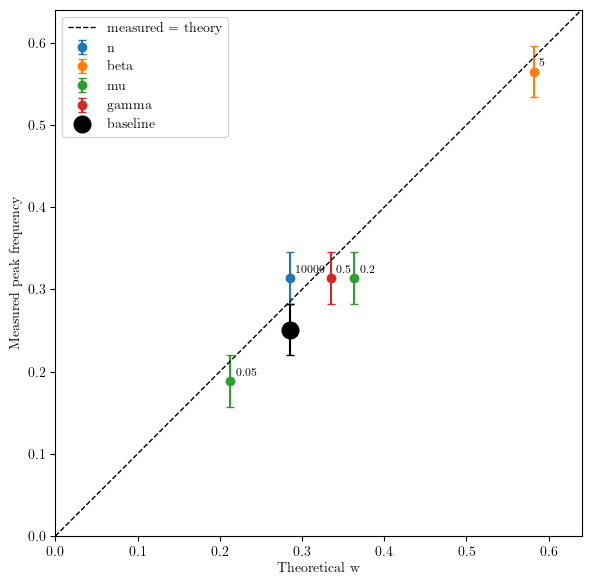

[{'param': 'n',
  'value': 1000,
  'is_baseline': True,
  'omega0': np.float64(0.28589427624575253),
  'omega_peak': np.float64(0.25107633595123224),
  'resolution': np.float64(0.06276908398780806),
  'n_used': 62},
 {'param': 'n',
  'value': 10000,
  'is_baseline': False,
  'omega0': np.float64(0.28589427624575253),
  'omega_peak': np.float64(0.3138454199390403),
  'resolution': np.float64(0.06276908398780806),
  'n_used': 100},
 {'param': 'beta',
  'value': 2,
  'is_baseline': True,
  'omega0': np.float64(0.28589427624575253),
  'omega_peak': np.float64(0.25107633595123224),
  'resolution': np.float64(0.06276908398780806),
  'n_used': 62},
 {'param': 'beta',
  'value': 5,
  'is_baseline': False,
  'omega0': np.float64(0.5816761190198688),
  'omega_peak': np.float64(0.5649217558902725),
  'resolution': np.float64(0.06276908398780806),
  'n_used': 100},
 {'param': 'mu',
  'value': 0.05,
  'is_baseline': False,
  'omega0': np.float64(0.212679162834197),
  'omega_peak': np.float64(0.1883

In [61]:
parity_plot()

To see how the transient is effected by the values of $R_0$ and $n$, we will perform a parameter sweep over the values stated before:



In [112]:
# We only want to perform a small amount of runs of a lot of different data
seeds_transient = range(10)
values_beta = np.arange(0.5,4.5,0.5)
values_N = np.linspace(10000,200,8, dtype = int)
print(values_beta)
print(values_N)

for n in values_N:
    baseline = dict(BASELINE, n=int(n))
    run_experiment("beta", values_beta, seeds=seeds_transient,
                   baseline=baseline, name=f"n_{n}_beta",
                   outdir="transient_data")

[0.5 1.  1.5 2.  2.5 3.  3.5 4. ]
[10000  8600  7200  5800  4400  3000  1600   200]
Running beta=0.5	:..........Complete
Running beta=1.0	:..........Complete
Running beta=1.5	:..........Complete
Running beta=2.0	:..........Complete
Running beta=2.5	:..........Complete
Running beta=3.0	:..........Complete
Running beta=3.5	:..........Complete
Running beta=4.0	:..........Complete
Running beta=0.5	:..........Complete
Running beta=1.0	:..........Complete
Running beta=1.5	:..........Complete
Running beta=2.0	:..........Complete
Running beta=2.5	:..........Complete
Running beta=3.0	:..........Complete
Running beta=3.5	:..........Complete
Running beta=4.0	:..........Complete
Running beta=0.5	:..........Complete
Running beta=1.0	:..........Complete
Running beta=1.5	:..........Complete
Running beta=2.0	:..........Complete
Running beta=2.5	:..........Complete
Running beta=3.0	:..........Complete
Running beta=3.5	:..........Complete
Running beta=4.0	:..........Complete
Running beta=0.5	:..........

We will then let each of the models burn in, with a a burn in time of $t_{burn}=100$. We will then compute the following:

\begin{align*}
    max|I/N- I^*|/ I^*
\end{align*}

We will do this for all combinations in our parameter sweep, and plot this in a heat map:

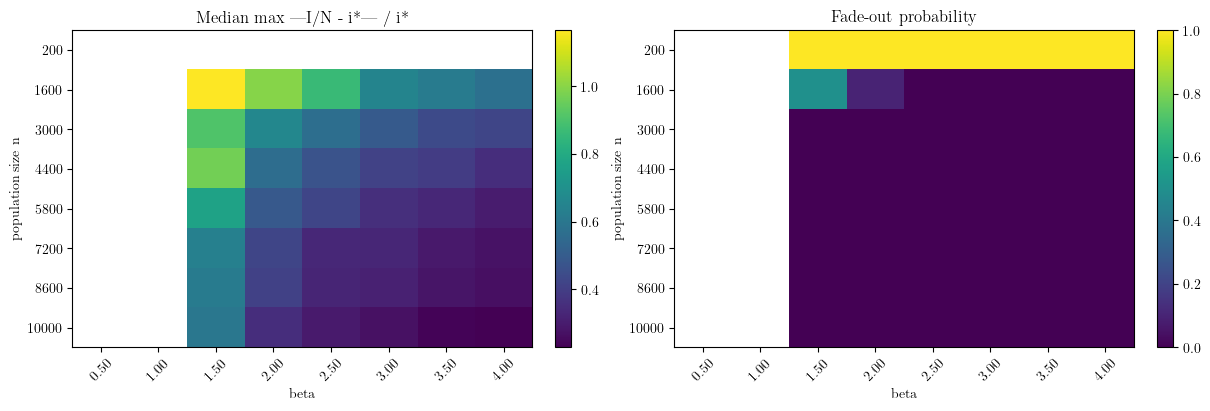

In [117]:
def transient_heatmap(values_N, values_beta, gamma=None, mu=None,
                      outdir="transient_data", t_burn=100, dt=None):
    gamma = BASELINE["gamma"] if gamma is None else gamma
    mu = BASELINE["mu"] if mu is None else mu
    dt = BASELINE["dt"] if dt is None else dt
    k0 = int(t_burn / dt)

    excursion = np.full((len(values_N), len(values_beta)), np.nan)
    fadeout = np.full_like(excursion, np.nan)

    for i, n in enumerate(values_N):
        stochastic, _ = load_experiment(f"n_{n}_beta", values_beta, outdir=outdir)
        for j, b in enumerate(values_beta):
            theory = equilibrium_theory(b, gamma, mu)
            if theory["R0"] <= 1:   
                # no endemic equilibrium
                continue
            i_star = theory["I"]
            runs = stochastic[b]
            # (seeds, time, 4)
            alive = runs[:, -1, 1] > 0
            fadeout[i, j] = 1 - alive.mean()
            if not alive.any():
                continue
            frac = runs[alive, k0:, 1] / runs[alive, k0:, 3]
            per_run = np.max(np.abs(frac - i_star), axis=1) / i_star
            excursion[i, j] = np.median(per_run)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    for ax, data, title in zip(axes, [excursion, fadeout],
                               ["Median max |I/N - i*| / i*", "Fade-out probability"]):
        im = ax.imshow(data, origin="lower", aspect="auto")
        ax.set_xticks(range(len(values_beta)), labels=[f"{b:.2f}" for b in values_beta],
                      rotation=45)
        ax.set_yticks(range(len(values_N)), labels=[str(n) for n in values_N])
        ax.set_xlabel("beta"); ax.set_ylabel("population size n")
        ax.set_title(title)
        fig.colorbar(im, ax=ax)
    plt.show()

transient_heatmap(values_N, values_beta)
#ToDo maybe change the values and do a rerun to only perform on R_0>1, cause we kinda know already that that will not be interesting.
# Also maybe larger population size, but I find it hard to set a boundary
# Also put R_0 on axis, not beta. and maybe a logerithmic groth of the popBut maybe not. 
# tbh I have no clue what fade prob even means (._.)